In [3]:
#Definição das bibliotecas usadas
import pandas as pd #álgebra linear
import numpy as np #processamento de dados

import matplotlib as mpl
import matplotlib.pyplot as plt #visualização de dados
import seaborn as sns #visualização de dados 

############### PARAMETRIZAÇÃO PARA EXECUÇÃO #############
# 1 - para Jupyter/Outras IDEs; 
# 2 - para GoogleColab 
carga_dados = 1
##########################################################

if carga_dados == 1:
    #Carrega Série Temporal a partir de Planilha de Dados no formato de DataFrame
    import tkinter as tk
    from tkinter import filedialog
    root = tk.Tk()
    root.withdraw()
    caminho_arquivo = filedialog.askopenfilename()
    df = pd.read_csv(caminho_arquivo)
else:
    #Carrega Dados para GoogleColab
    import io
    from google.colab import files
    uploaded = files.upload()
    df = pd.read_csv(io.BytesIO(uploaded['Dataset1.csv']))

df

,Data,Preco
0,7/1/2009 0:00,14.25
1,7/1/2009 1:00,8.43
2,7/1/2009 2:00,1.88
3,7/1/2009 3:00,11.00
4,7/1/2009 4:00,4.21
...,...,...
1003,8/11/2009 19:00,33.12
1004,8/11/2009 20:00,38.14
1005,8/11/2009 21:00,34.04
1006,8/11/2009 22:00,20.80


In [5]:
df['Preco'].describe()

count    1008.000000
mean       19.642411
std        14.662304
min         0.000000
25%         6.770000
50%        18.995000
75%        29.710000
max       237.760000
Name: Preco, dtype: float64

In [7]:
df['DateTime'] = pd.to_datetime(df['Data'])
df

,Data,Preco,DateTime
0,7/1/2009 0:00,14.25,2009-07-01 00:00:00
1,7/1/2009 1:00,8.43,2009-07-01 01:00:00
2,7/1/2009 2:00,1.88,2009-07-01 02:00:00
3,7/1/2009 3:00,11.00,2009-07-01 03:00:00
4,7/1/2009 4:00,4.21,2009-07-01 04:00:00
...,...,...,...
1003,8/11/2009 19:00,33.12,2009-08-11 19:00:00
1004,8/11/2009 20:00,38.14,2009-08-11 20:00:00
1005,8/11/2009 21:00,34.04,2009-08-11 21:00:00
1006,8/11/2009 22:00,20.80,2009-08-11 22:00:00


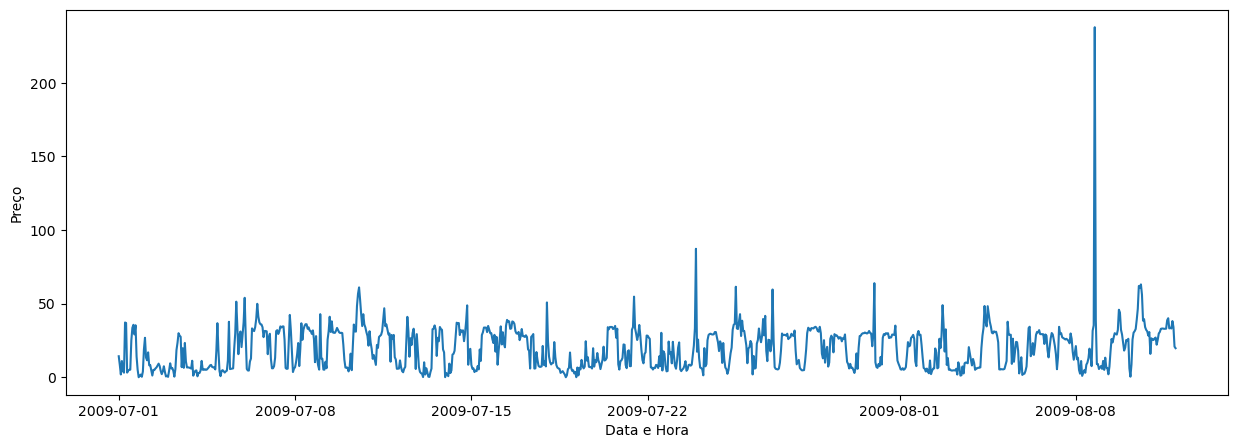

In [9]:
plt.figure(figsize=(15,5))
plt.plot(df['DateTime'], df['Preco'])
plt.ylabel('Preço')
plt.xlabel('Data e Hora')
plt.show()

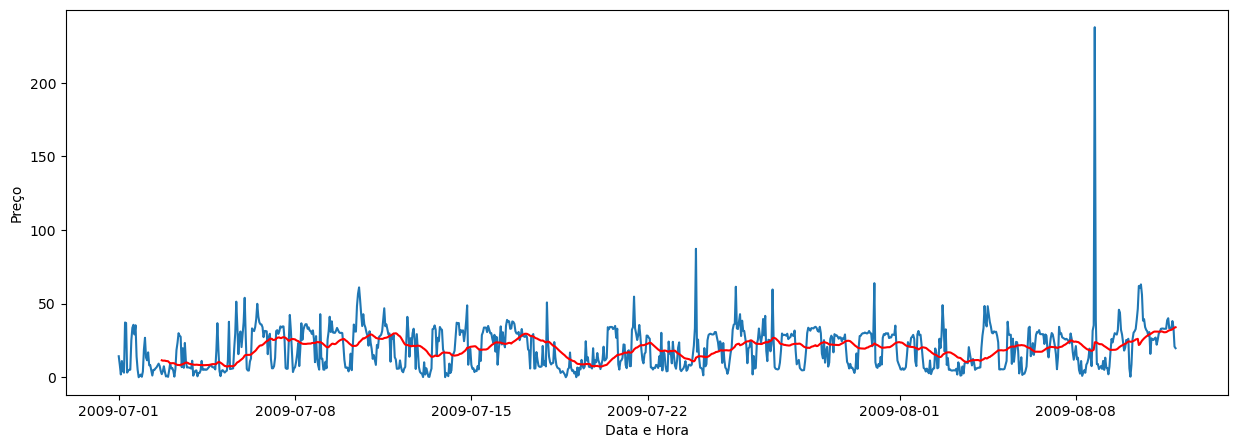

In [11]:
# Média Móvel como Suavização de Dados
tamanho_janela = 42
df['MA_Suavizacao'] = df['Preco'].rolling(tamanho_janela).mean()

plt.figure(figsize=(15,5))
plt.plot(df['DateTime'], df['Preco'])
plt.plot(df['DateTime'], df['MA_Suavizacao'], 'r')
plt.ylabel('Preço')
plt.xlabel('Data e Hora')
plt.show()

In [13]:
#Torna a Coluna DateTime o índice do DataFrame
df = df.set_index(df['DateTime'])

#Clona o DataFrame e Normaliza as Colunas pela primeira amostra
df_clone = df[:]
df_clone['Preco'] = df['Preco'] / df['Preco'].iloc[0]

#Copia apenas as colunas de interesse do Clone para o novo DataFrame
df_norm = df_clone[['Preco']]

#Clona o DataFrame normalizado para um novo
df_lagged = df_norm[:]

#Determina os atrasos (em amostras)
lag = 1

#Gera o DataFrame com as Colunas de Atraso
#df_lagged = df_norm.assign(**{f'{col}_t-{lag}': df_norm[col].shift(lag) for lag in lags for col in df_norm})
df_lagged = df_norm.assign(**{f'{col}_t-{lag}': df_norm[col].shift(lag) for col in df_norm})

#Exclui valor NaN
df_proc = df_lagged.dropna()

#Mostra dados mais recentes
df_proc

,Preco,Preco_t-1
DateTime,,
2009-07-01 01:00:00,0.591579,1.000000
2009-07-01 02:00:00,0.131930,0.591579
2009-07-01 03:00:00,0.771930,0.131930
2009-07-01 04:00:00,0.295439,0.771930
2009-07-01 05:00:00,0.216140,0.295439
...,...,...
2009-08-11 19:00:00,2.324211,2.353684
2009-08-11 20:00:00,2.676491,2.324211
2009-08-11 21:00:00,2.388772,2.676491


In [15]:
#Define as colunas que serão variáveis de entrada - explicativas
features = df_proc.columns[[1]]
features

Index(['Preco_t-1'], dtype='object')

In [17]:
#Define as coluna que será variável de saída - interesse
target = df_proc.columns[[0]]
target

Index(['Preco'], dtype='object')

In [19]:
#Separação de Dados para Ajuste e Validação dos Modelos
df_t_ajuste = df_proc['2009-07-01 00:00:00':'2009-07-31 23:00:00'].index.values
df_t_validacao = df_proc['2009-08-01 00:00:00':].index.values
df_dados_ajuste = df_proc['2009-07-01 00:00:00':'2009-07-31 23:00:00']
df_dados_validacao = df_proc['2009-08-01 00:00:00':]

X_ajuste = df_dados_ajuste[features].values
Y_ajuste = df_dados_ajuste[target].values
X_validacao = df_dados_validacao[features].values
Y_validacao = df_dados_validacao[target].values

In [27]:
# Parametrização de Modelo AR
from statsmodels.tsa.arima.model import ARIMA
AR_model = ARIMA(X_ajuste, order=(15, 0, 0)) #order = (p,d,q)
AR_param = AR_model.fit()
AR_param.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:                      y   No. Observations:                  743
Model:                ARIMA(15, 0, 0)   Log Likelihood                -712.579
Date:                Sun, 28 Jul 2024   AIC                           1459.158
Time:                        19:30:37   BIC                           1537.539
Sample:                             0   HQIC                          1489.373
                                - 743                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.3440      0.101     13.285      0.000       1.146       1.542
ar.L1          0.6326      0.024     26.278      0.000       0.585       0.680
ar.L2          0.0876      0.041      2.160      0.031       0.008       0.167
ar.L3          0.0029      0.044      0.066      0.947      -0.083       0.089
ar.L4          0.0564      0.044      1.269      0.204      -0.031       0.144
ar.L5         -0.0643      0.052     -1.233      0.218      -0.167       0.038
ar.L6          0.0559      0.051      1.105      0.269      -0.043       0.155
ar.L7          0.0230      0.042      0.555      0.579      -0.058       0.104
ar.L8         -0.0338      0.041     -0.825      0.409      -0.114       0.046
ar.L9          0.0016      0.047      0.034      0.973      -0.091       0.094
ar.L10        -0.0790      0.052     -1.531      0.126      -0.180       0.022
ar.L11         0.0294      0.046      0.635      0.525      -0.061       0.120
ar.L12        -0.0395      0.049     -0.811      0.417      -0.135       0.056
ar.L13        -0.0125      0.054     -0.232      0.816      -0.118       0.093
ar.L14         0.0427      0.060      0.711      0.477      -0.075       0.161
ar.L15         0.0263      0.046      0.565      0.572      -0.065       0.117
sigma2         0.3981      0.013     29.874      0.000       0.372       0.424
===================================================================================
Ljung-Box (L1) (Q):                   0.00   Jarque-Bera (JB):               823.84
Prob(Q):                              1.00   Prob(JB):                         0.00
Heteroskedasticity (H):               1.16   Skew:                             0.59
Prob(H) (two-sided):                  0.26   Kurtosis:                         8.02
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

In [29]:
df_previsto_AR = AR_param.predict(start=len(X_validacao), end=len(X_validacao)+len(X_validacao)-1)
df_previsto_AR_denorm = df_previsto_AR * df['Preco'].iloc[0]

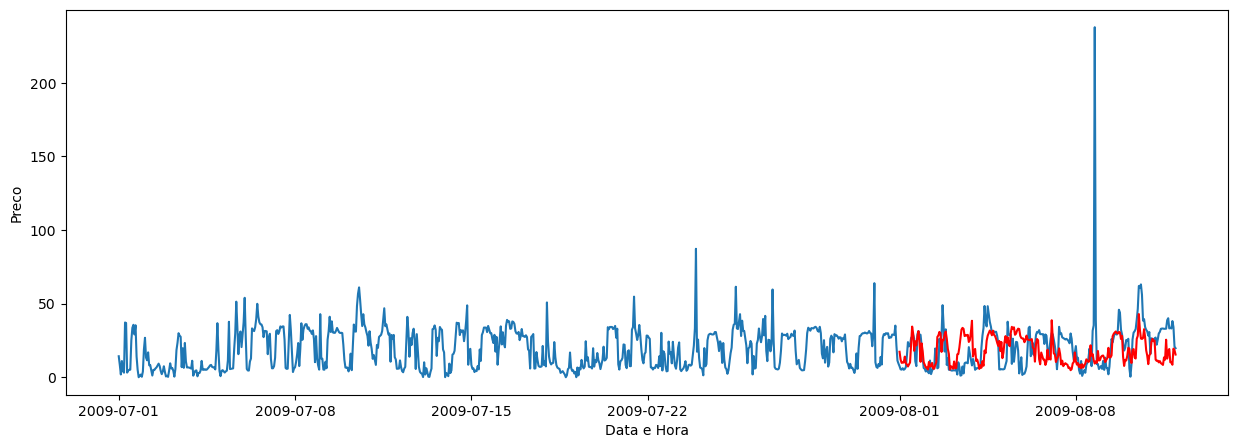

In [31]:
plt.figure(figsize=(15,5))
plt.plot(df['DateTime'], df['Preco'])
plt.plot(df_t_validacao, df_previsto_AR_denorm, 'r')
plt.ylabel('Preco')
plt.xlabel('Data e Hora')
plt.show()